# Forecasting with `sktime` — a hands-on workshop

**Sovereign AI Meetup Ulm · 17 November 2026**

You will learn how to forecast time series with [`sktime`](https://www.sktime.net), an open-source library with **one unified interface** for classical statistics, machine learning, and foundation models.

| Block | Topic | Time |
|---|---|---|
| 0 | Setup check | 20 min |
| 1 | Basic forecasting: `fit` / `predict`, evaluation, backtesting, ML models | 86 min |
| – | Break | 15 min |
| 2 | Pipelines, tuning, prediction intervals | 57 min |
| 3 | Many series at once: panel and hierarchical data | 32 min |
| 4 | Foundation models as drop-in forecasters | 37 min |
| – | Wrap-up | 5 min |

**How this works:** short explanations, live demos, and **exercises** (✏️) for you. Cells with `...` are yours to fill in. Bonus exercises (🌟) are for when you are faster than the rest.

## What is `sktime`?

`sktime` is an open-source Python library for machine learning with time series. If you know `scikit-learn`, you already know the core idea:

1. **Pick** a model and set its parameters.
2. **`fit`** it on your data.
3. **`predict`**.

Want a different model? Change line 1. Lines 2 and 3 stay the same. That is the whole trick, and it works for ARIMA, random forests, and neural networks alike.

Time series are more than forecasting, and `sktime` covers all of it: **forecasting**, **classification**, **regression**, **clustering**, and **detection** of anomalies and changepoints. Today we only do forecasting, but everything you learn carries over.

Why does this matter? The Python time series world is a zoo. Every package has its own interface, and combining them is painful. `sktime` wraps many of them (statsmodels, pytorch-forecasting, Chronos, ...) behind one interface, so you can **swap, combine, and compare** models without rewriting your code. You will see this in Block 4, where a foundation model drops in just like `NaiveForecaster`.

`sktime` is community-driven and open source, with no vendor lock-in. Contributors are welcome, also beginners: [Discord](https://discord.com/invite/54ACzaFsn7) · [GitHub](https://github.com/sktime/sktime) · [Docs](https://www.sktime.net)

⏱️ **Instructor timing**

**0:00-0:20 · Intro and Block 0 (20 min).** Intro talk 5 min, setup check 15 min: with a full room, someone always has a broken environment or a slow download. Do not wait for everybody, help stragglers during the next section.

## Block 0 · Setup check (20 min)

In [1]:
import logging
import os
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"  # also for worker processes
os.environ["HF_HUB_VERBOSITY"] = "error"  # no Hugging Face hints
logging.getLogger("transformers").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")  # keep the output clean for the workshop
warnings.filterwarnings("ignore", category=FutureWarning)  # sktime announces future changes, not relevant today
warnings.showwarning = lambda *args, **kwargs: None  # some libraries re-enable warnings on import
warnings.warn = lambda *args, **kwargs: None  # last resort: some libraries reset the filters themselves

import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sktime

print("python ", sys.version.split()[0])
print("sktime ", sktime.__version__)
print("pandas ", pd.__version__)

plt.rcParams["figure.figsize"] = (10, 3.5)
C_BLUE, C_ORANGE = "#1f6fb4", "#e07b00"

python  3.11.16
sktime  1.2.0
pandas  3.0.6


**Block 4 uses a pre-trained foundation model** that is downloaded once (about 35 MB) from Hugging Face. The next cell tests this now, so we find problems early.

In [2]:
# Test that the foundation model of Block 4 can be loaded.
# This needs internet once; afterwards the model is cached on your disk.
from sktime.datasets import load_airline
from sktime.forecasting.chronos import ChronosForecaster

CHRONOS_OK = False
try:
    from transformers.utils import logging as hf_logging

    hf_logging.set_verbosity_error()
    ChronosForecaster("amazon/chronos-bolt-tiny").fit(load_airline(), fh=[1, 2])
    CHRONOS_OK = True
    print("✅ Chronos is ready.")
except Exception as e:  # noqa: BLE001
    print("⚠️ Could not load Chronos (no internet?). Blocks 1-3 work without it.")
    print("   In Block 4, the first demo has an offline fallback.")
    print("   Error:", type(e).__name__, str(e)[:150])

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

✅ Chronos is ready.


⏱️ **Instructor timing**

**0:20-0:25 · 1.1 the data (5 min).**

---
# Block 1 · Basic forecasting (86 min)

## 1.1 The data

The classic *airline passengers* dataset: monthly international airline passengers 1949-1960. It has a **trend** and a **seasonality that grows with the level**.

In [3]:
from sktime.datasets import load_airline

y = load_airline()
y.head()

Period
1949-01    112.0
1949-02    118.0
1949-03    132.0
1949-04    129.0
1949-05    121.0
Freq: M, Name: Number of airline passengers, dtype: float64

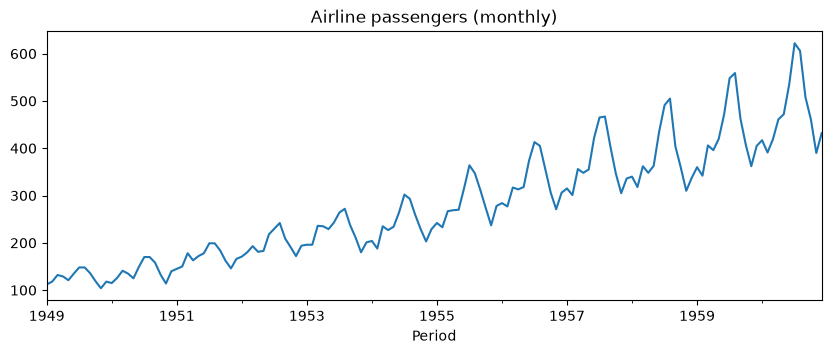

In [4]:
y.plot(title="Airline passengers (monthly)");

`sktime` works with plain `pandas` objects. The index here is a `PeriodIndex` with monthly frequency. A `DatetimeIndex` or an integer index would work too.

⏱️ **Instructor timing**

**0:25-0:43 · 1.2 fit/predict + swap exercise (18 min).** Exercise 6 min including the solution. The registry cell is a 1-min aside.

## 1.2 `fit` and `predict`

Every forecaster in `sktime` follows the same recipe:

1. **specify** the algorithm
2. **specify** the forecasting horizon `fh` (which steps do we want?)
3. **`fit`** on the history
4. **`predict`** the future

Let's start with the simplest forecaster: *repeat what happened one year ago* (seasonal naive).

In [5]:
from sktime.forecasting.naive import NaiveForecaster

# step 1: the algorithm. "last" value, with a season of length 12 -> same month last year
naive = NaiveForecaster(strategy="last", sp=12)

# step 2: the horizon: the next 24 months
fh = np.arange(1, 25)

# step 3 and 4
naive.fit(y, fh=fh)
y_pred = naive.predict()

y_pred.head(3)

1961-01    417.0
1961-02    391.0
1961-03    419.0
Freq: M, Name: Number of airline passengers, dtype: float64

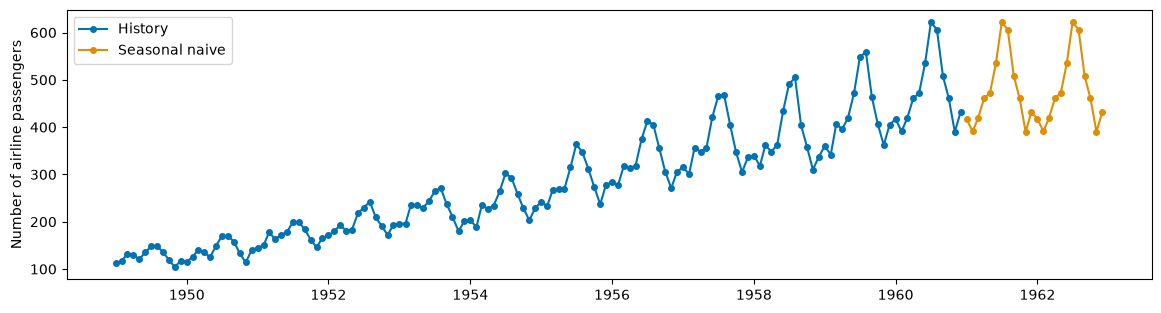

In [6]:
from sktime.utils.plotting import plot_series

plot_series(y, y_pred, labels=["History", "Seasonal naive"]);

### ✏️ Exercise: Swap the forecaster

Use **exponential smoothing** (ETS) instead of the naive forecaster. Same recipe, only step 1 changes.

* Create `ExponentialSmoothing(trend="add", seasonal="mul", sp=12)`
* `fit` it on `y`, `predict` the horizon `fh`
* plot history and forecast with `plot_series`

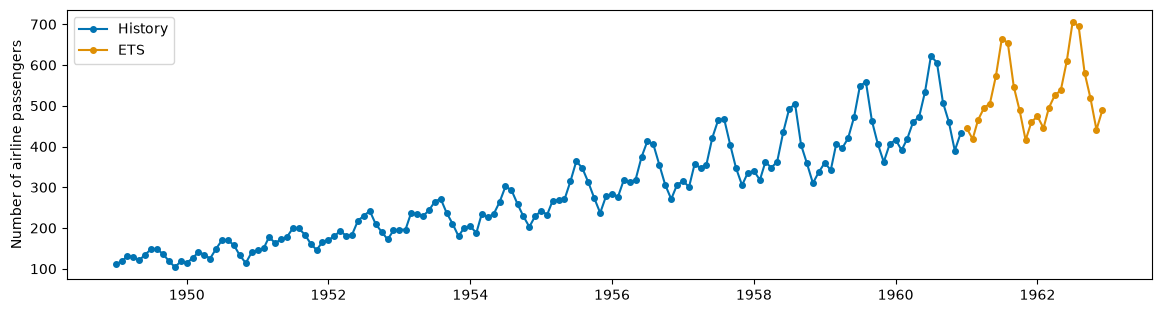

In [7]:
# --- Solution (instructor version only) ---
from sktime.forecasting.exp_smoothing import ExponentialSmoothing

ets = ExponentialSmoothing(trend="add", seasonal="mul", sp=12)
ets.fit(y, fh=fh)
y_pred_ets = ets.predict()

plot_series(y, y_pred_ets, labels=["History", "ETS"]);

Same methods, completely different algorithm. That is the point of `sktime`: **you can swap models without rewriting your code.**

*(If you skipped the exercise, run this cell so the rest works.)*

In [8]:
from sktime.forecasting.exp_smoothing import ExponentialSmoothing

ets = ExponentialSmoothing(trend="add", seasonal="mul", sp=12)

How many forecasters are there? The registry knows:

In [9]:
from sktime.registry import all_estimators

forecasters = all_estimators(estimator_types="forecaster", as_dataframe=True)
print(len(forecasters), "forecasters")
forecasters.head(10)

160 forecasters


,name,object
0,ARARForecaster,<class 'sktime.forecasting.arar._arar_forecast...
1,ARCH,<class 'sktime.forecasting.arch._uarch.ARCH'>
2,ARDL,<class 'sktime.forecasting.ardl.ARDL'>
3,ARIMA,<class 'sktime.forecasting.arima._pmdarima.ARI...
4,ArpsExponential,<class 'sktime.forecasting.arps_dca.ArpsExpone...
5,ArpsHarmonic,<class 'sktime.forecasting.arps_dca.ArpsHarmon...
6,ArpsHyperbolic,<class 'sktime.forecasting.arps_dca.ArpsHyperb...
7,AuroraForecaster,<class 'sktime.forecasting.aurora.AuroraForeca...
8,AutoARIMA,<class 'sktime.forecasting.arima._pmdarima.Aut...
9,AutoETS,<class 'sktime.forecasting.ets.AutoETS'>


Looking for a specific model? Try the **estimator search** on the website: <https://www.sktime.net/en/latest/estimator_overview.html>. You can filter by task and by capabilities, such as prediction intervals or exogenous data.

⏱️ **Instructor timing**

**0:43-0:53 · 1.3 train/test split and metrics (10 min).**

## 1.3 How good is a forecast?

To judge a forecast, we hide the last part of the data (**test set**), forecast it, and compare. Unlike in scikit-learn, we must **not shuffle**: the test set is always the *end* of the series.

<img src="imgs/split.png" style="max-width: 900px" />

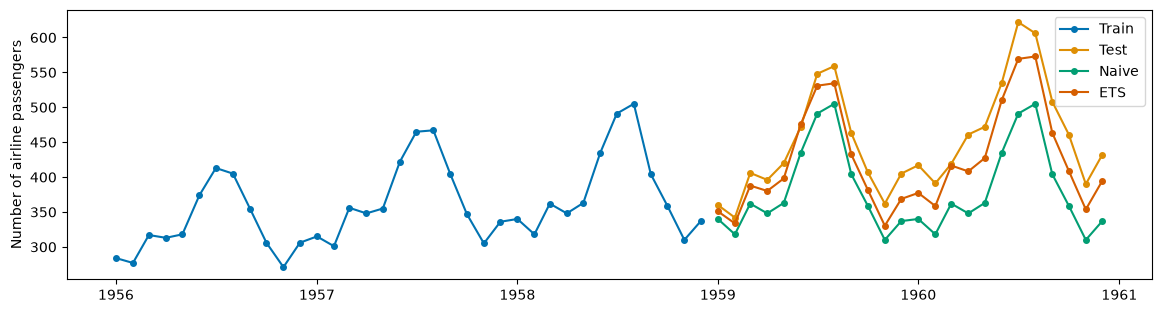

In [10]:
from sktime.split import temporal_train_test_split

y_train, y_test = temporal_train_test_split(y, test_size=24)

naive.fit(y_train, fh=fh)
ets.fit(y_train, fh=fh)

plot_series(
    y_train.tail(36),
    y_test,
    naive.predict(),
    ets.predict(),
    labels=["Train", "Test", "Naive", "ETS"],
);

In [11]:
from sktime.performance_metrics.forecasting import (
    MeanAbsoluteError,
    MeanAbsolutePercentageError,
)

mae = MeanAbsoluteError()
mape = MeanAbsolutePercentageError()

for name, model in [("Naive", naive), ("ETS", ets)]:
    y_hat = model.predict()
    print(f"{name:6} MAE: {mae(y_test, y_hat):6.1f}   MAPE: {mape(y_test, y_hat):.1%}")

Naive  MAE:   71.2   MAPE: 15.5%
ETS    MAE:   29.0   MAPE: 6.4%


⏱️ **Instructor timing**

**0:53-1:18 · 1.4 backtesting + exercise (25 min).** The splitter plot and the `backtest` helper need time to land. Exercise 6 min. ✅ Checkpoint 1:18: the `backtest` helper must be defined, it is used all day.

## 1.4 Backtesting: one test set is not enough

A single test set can be lucky or unlucky. **Backtesting** (also: time series cross-validation) repeats the experiment on several windows: fit on the past, forecast the next 12 months, move the window forward, repeat.

We define the splitter **once** and use it for the whole workshop.

<img src="imgs/backtest.gif" style="max-width: 800px" />

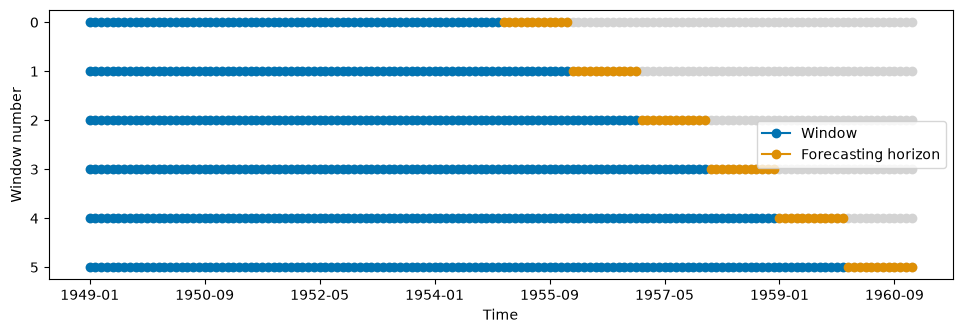

In [12]:
from sktime.split import ExpandingWindowSplitter
from sktime.utils.plotting import plot_windows

cv = ExpandingWindowSplitter(fh=np.arange(1, 13), initial_window=72, step_length=12)

plot_windows(cv=cv, y=y);

In [13]:
from sktime.forecasting.model_evaluation import evaluate

results = evaluate(forecaster=ets, cv=cv, y=y, scoring=mape)
results[["test_MeanAbsolutePercentageError", "fit_time"]]

,test_MeanAbsolutePercentageError,fit_time
0,0.064851,0.130935
1,0.028211,0.103381
2,0.036643,0.197974
3,0.041996,0.142704
4,0.047904,0.087845
5,0.022074,0.110912


One row per window. Let's wrap this in a small helper that returns the **average error over all windows**. We will reuse it all day.

In [14]:
def backtest(forecaster, y=y, cv=cv):
    """Mean MAPE over all backtest windows (lower is better)."""
    res = evaluate(forecaster=forecaster, cv=cv, y=y, scoring=mape)
    return float(res["test_MeanAbsolutePercentageError"].mean())


backtest(naive), backtest(ets)

(0.1071126074773769, 0.04028002513415251)

### ✏️ Exercise: Which forecaster wins?

Backtest **three** forecasters with the `backtest` helper and print them sorted by error (best first):

* `NaiveForecaster(strategy="last", sp=12)`
* `ExponentialSmoothing(trend="add", seasonal="mul", sp=12)`
* `ThetaForecaster(sp=12)` (from `sktime.forecasting.theta`)

*Hint: put them in a dictionary and loop over it.*

In [15]:
# --- Solution (instructor version only) ---
from sktime.forecasting.theta import ThetaForecaster

candidates = {
    "naive": NaiveForecaster(strategy="last", sp=12),
    "ets": ExponentialSmoothing(trend="add", seasonal="mul", sp=12),
    "theta": ThetaForecaster(sp=12),
}

scores = {name: backtest(f) for name, f in candidates.items()}
pd.Series(scores).sort_values()

ets      0.040280
theta    0.063929
naive    0.107113
dtype: float64

⏱️ **Instructor timing**

**1:18-1:28 · 1.5 exogenous variables (10 min). ⏭️ SKIPPABLE (-10 min).** Nothing later depends on it (`y_lg`, `ForecastX` are only used here). If you skip it, subtract 10 min from all following times.

## 1.5 Exogenous variables

Sometimes we know more than the history: weather, prices, promotions. In `sktime`, such **exogenous variables** are passed as `X`. Example: *US employment* (`y`) and macro-economic indicators (`X`).

In [16]:
from sktime.datasets import load_longley

y_lg, X_lg = load_longley()
X_lg.head(3)

,GNPDEFL,GNP,UNEMP,ARMED,POP
Period,,,,,
1947,83.0,234289.0,2356.0,1590.0,107608.0
1948,88.5,259426.0,2325.0,1456.0,108632.0
1949,88.2,258054.0,3682.0,1616.0,109773.0


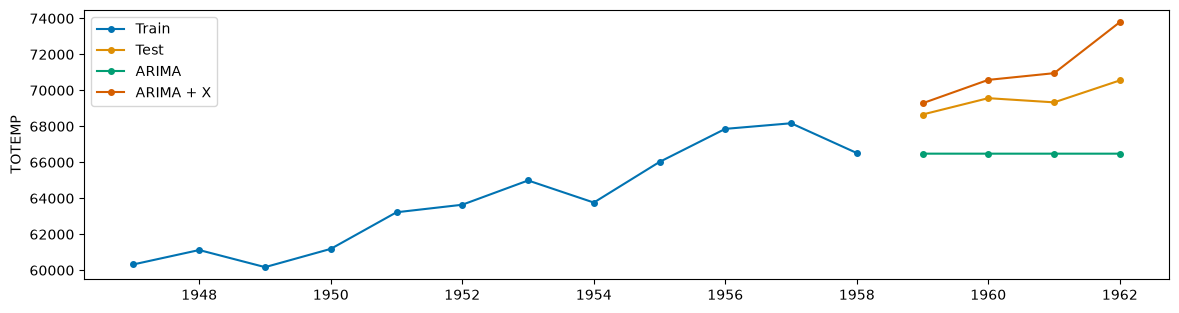

In [17]:
from sktime.forecasting.arima import StatsModelsARIMA

y_lg_train, y_lg_test, X_lg_train, X_lg_test = temporal_train_test_split(
    y_lg, X_lg, test_size=4
)
fh_lg = np.arange(1, 5)

arima = StatsModelsARIMA(order=(1, 1, 0)).fit(y_lg_train, fh=fh_lg)
arimax = StatsModelsARIMA(order=(1, 1, 0)).fit(y_lg_train, X=X_lg_train, fh=fh_lg)

plot_series(
    y_lg_train,
    y_lg_test,
    arima.predict(),
    arimax.predict(X=X_lg_test),
    labels=["Train", "Test", "ARIMA", "ARIMA + X"],
);

With `X`, the forecast looks better. But wait: in this evaluation we **knew the true values of `X` in the test period**. In real life, we want to forecast the *future*, and nobody gives us `X` for next year. Let's do it for real: fit on **all** data and predict the next 4 years.

In [18]:
arimax_full = StatsModelsARIMA(order=(1, 1, 0)).fit(y_lg, X=X_lg, fh=fh_lg)

try:
    arimax_full.predict()  # no future X provided
except ValueError as e:
    print("❌ ValueError:", e)

❌ ValueError: Out-of-sample operations in a model with a regression component require additional exogenous values via the `exog` argument.


💥 **It fails.** To forecast `y`, the model needs the **future values of `X`**, and we don't have them. This is a very common trap with exogenous variables: *if you cannot know `X` in the future, you cannot use it directly.*

The fix: **forecast `X` as well.** That is what `ForecastX` does. It wraps two forecasters:

* `forecaster_X` forecasts every column of `X` into the future (**a second forecast!**)
* `forecaster_y` then uses these forecasted values as the future `X`

<img src="imgs/forecastx.gif" style="max-width: 700px" />

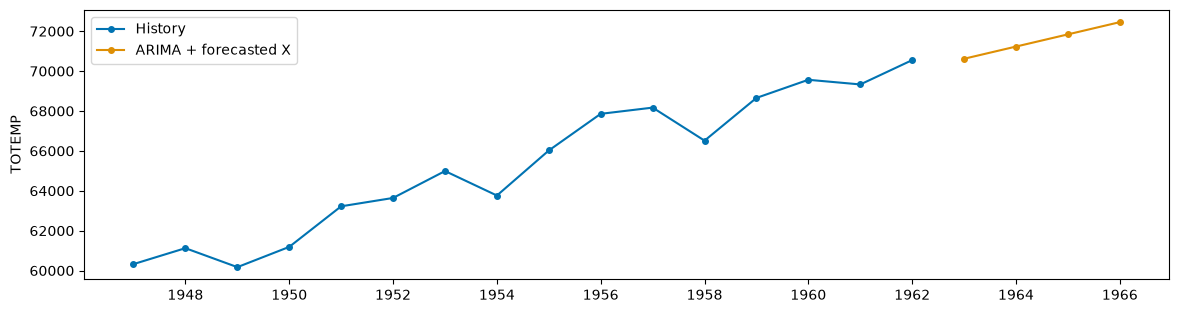

In [19]:
from sktime.forecasting.compose import ForecastX

arimax_plus_exo = ForecastX(
    forecaster_y=StatsModelsARIMA(order=(1, 1, 0)),
    forecaster_X=ExponentialSmoothing(trend="add"),
)

arimax_plus_exo.fit(y_lg, X=X_lg, fh=fh_lg)  # no future X needed
y_pred_lg = arimax_plus_exo.predict()

plot_series(y_lg, y_pred_lg, labels=["History", "ARIMA + forecasted X"]);

It works without us providing any future `X`. Let's look under the hood: the inner forecaster for `X` made its own forecasts, one column per exogenous variable, and these were fed into the ARIMA.

In [20]:
arimax_plus_exo.forecaster_X_.predict()

,GNPDEFL,GNP,UNEMP,ARMED,POP
Period,,,,,
1963,120.777500,563894.272844,4308.200036,2909.468804,132318.060277
1964,123.024118,584600.947398,4439.363248,2991.937611,134555.120554
1965,125.270735,605307.621952,4570.526460,3074.406418,136792.180832
1966,127.517353,626014.296506,4701.689672,3156.875225,139029.241109


⏱️ **Instructor timing**

**1:28-1:46 · 1.6 reduction + random forest exercise (18 min).** Two animations to explain, exercise 5 min. ✅ Checkpoint 1:46 (1:36 without 1.5): Block 1 done. Then **break 15 min** (1:46-2:01).

## 1.6 Machine learning models as forecasters (*reduction*)

Can we use any scikit-learn regressor, like linear regression or random forest? Yes, with a trick called **reduction**: cut the series into windows, where the previous 12 values are the features and the next value is the target. Then it's a normal tabular regression problem.

<img src="imgs/reduction.gif" style="max-width: 800px" />

**But how do we forecast several steps ahead?** The model only predicts *one* step. `make_reduction` uses the **recursive** strategy by default: predict one step, treat the prediction as if it were an observation, and predict the next step from the updated window.

<img src="imgs/recursive.gif" style="max-width: 800px" />

`sktime` does the windowing and the recursion for us with `make_reduction`. The resulting object is a normal `sktime` forecaster.

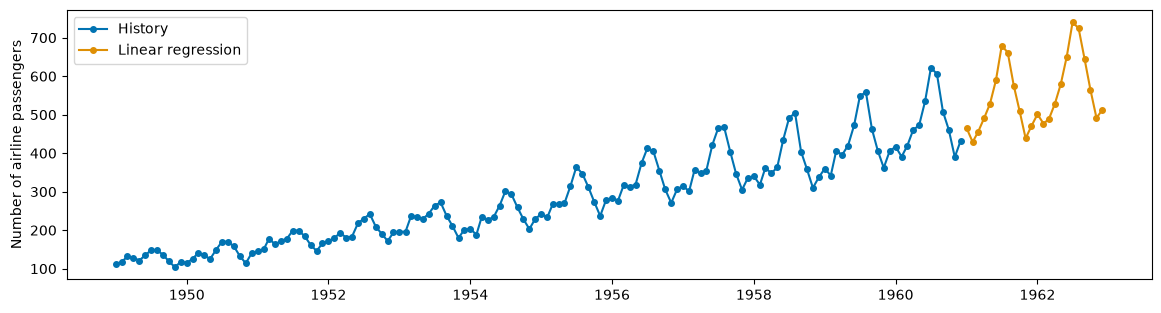

In [21]:
from sklearn.linear_model import LinearRegression
from sktime.forecasting.compose import make_reduction

lr_forecaster = make_reduction(LinearRegression(), window_length=12)
lr_forecaster.fit(y, fh=fh)

plot_series(y, lr_forecaster.predict(), labels=["History", "Linear regression"]);

### ✏️ Exercise: A non-linear model

Replace the linear regression with a `RandomForestRegressor` (or any other scikit-learn regressor), again with `window_length=12`.

Plot the forecast. **What do you notice at the end of the forecast? Why might this happen?**

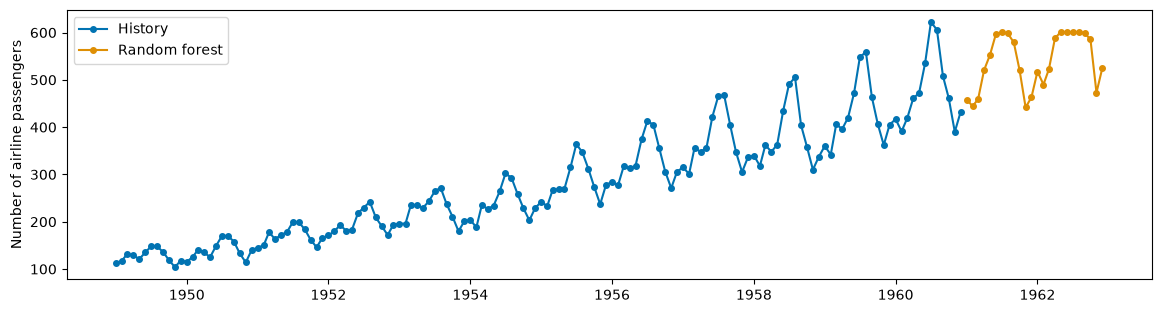

In [22]:
# --- Solution (instructor version only) ---
from sklearn.ensemble import RandomForestRegressor

rf_forecaster = make_reduction(RandomForestRegressor(random_state=0), window_length=12)
rf_forecaster.fit(y, fh=fh)

plot_series(y, rf_forecaster.predict(), labels=["History", "Random forest"]);

# Answer: the forecast stays on the level of the past. A tree can only output values
# it has seen in training (averages of leaves), so it cannot extrapolate the trend.

**Why is the forecast flat?** A tree predicts averages of training values. It can never output a value larger than the ones it has seen, so it cannot continue a trend.

<img src="imgs/trees.png" style="max-width: 700px" />

⏱️ **Instructor timing**

**2:01-2:23 · 2.1 pipelines + exercise (22 min).** Exercise 7 min.

---
# Block 2 · Pipelines, tuning, intervals (57 min)

## 2.1 Fixing the random forest with a pipeline

Trees cannot extrapolate a trend, but we can **remove the trend** before the model sees the data, and add it back afterwards. Also, the seasonal swings grow over time, which a `log` transform stabilises.

`sktime` has transformers for this. A `TransformedTargetForecaster` chains them with a forecaster, just like a scikit-learn `Pipeline`:

`log → detrend → random forest`, and the *inverse* of every step is applied automatically on `predict`.

<img src="imgs/pipeline.png" style="max-width: 1000px" />

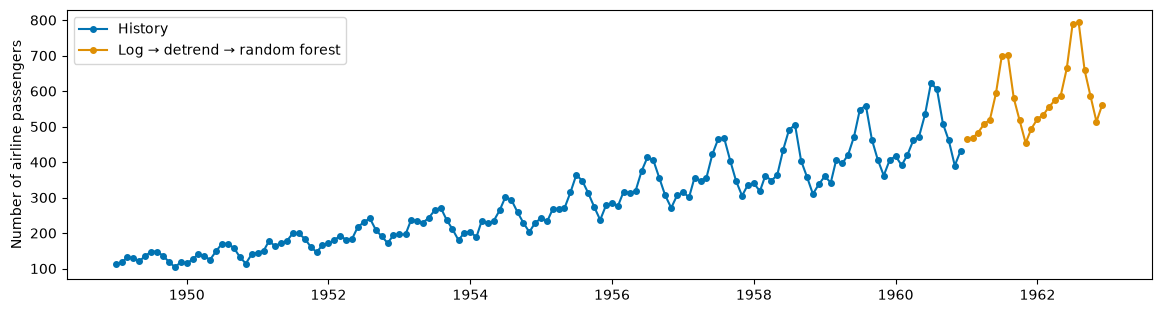

In [23]:
from sklearn.ensemble import RandomForestRegressor
from sktime.forecasting.compose import TransformedTargetForecaster
from sktime.transformations.series.boxcox import LogTransformer
from sktime.transformations.series.detrend import Detrender

pipe = TransformedTargetForecaster(
    [
        ("log", LogTransformer()),
        ("detrend", Detrender()),
        ("forecast", make_reduction(RandomForestRegressor(random_state=0), window_length=12)),
    ]
)

pipe.fit(y, fh=fh)
plot_series(y, pipe.predict(), labels=["History", "Log → detrend → random forest"]);

Much better. And there is a shortcut: the `*` operator chains steps.

In [24]:
from sktime.transformations.series.detrend import Deseasonalizer

rf = make_reduction(RandomForestRegressor(random_state=0), window_length=12)

pipe_long = LogTransformer() * Deseasonalizer(sp=12, model="multiplicative") * Detrender() * rf

pipe_long

TransformedTargetForecaster(steps=[LogTransformer(),
                                   Deseasonalizer(model='multiplicative',
                                                  sp=12),
                                   Detrender(),
                                   RecursiveTabularRegressionForecaster(estimator=RandomForestRegressor(random_state=0),
                                                                        window_length=12)])

In [25]:
backtest(rf), backtest(pipe), backtest(pipe_long)

(0.08593265223112852, 0.04203411473996529, 0.04175111702909585)

### ✏️ Exercise: Build your own pipeline

Build **your own** pipeline with the `*` operator:

1. `Deseasonalizer(sp=12, model="multiplicative")`
2. `Detrender()`
3. `make_reduction(...)` with a regressor of your choice (e.g. `GradientBoostingRegressor`, `KNeighborsRegressor`, `Ridge`) and `window_length=12`

Backtest it with `backtest(...)`. Can you beat the pipelines above?

In [26]:
# --- Solution (instructor version only) ---
from sklearn.ensemble import GradientBoostingRegressor

my_pipe = (
    Deseasonalizer(sp=12, model="multiplicative")
    * Detrender()
    * make_reduction(GradientBoostingRegressor(random_state=0), window_length=12)
)

backtest(my_pipe)

0.06435943198534766

⏱️ **Instructor timing**

**2:23-2:40 · 2.2 tuning + exercise (17 min).** Exercise 6 min. Let the grid search run while you explain. If short on time: show the ETS tuning only and demo the pipeline tuning live.

## 2.2 Hyperparameter tuning

Which parameters are good? Let `sktime` search, with backtesting as the judge: `ForecastingGridSearchCV` is a forecaster that wraps another forecaster and tunes it.

First on a simple model, ETS:

In [27]:
from sktime.forecasting.model_selection import ForecastingGridSearchCV
from sktime.split import ExpandingGreedySplitter

tuned_ets = ForecastingGridSearchCV(
    forecaster=ExponentialSmoothing(seasonal="multiplicative", sp=12),
    param_grid={
        "trend": ["add", "mul"],
        "damped_trend": [True, False],
    },
    cv=ExpandingGreedySplitter(test_size=12, folds=3),
    backend="threading",  # run the search in threads
)
tuned_ets.fit(y, fh=fh)

tuned_ets.best_params_

{'damped_trend': False, 'trend': 'add'}

In [28]:
tuned_ets.cv_results_.sort_values("rank_test_MeanAbsolutePercentageError")

,mean_test_MeanAbsolutePercentageError,mean_fit_time,mean_pred_time,params,rank_test_MeanAbsolutePercentageError
2,0.037325,0.395078,0.024987,"{'damped_trend': False, 'trend': 'add'}",1.0
0,0.038929,0.346057,0.060991,"{'damped_trend': True, 'trend': 'add'}",2.0
3,0.058636,0.664681,0.018175,"{'damped_trend': False, 'trend': 'mul'}",3.0
1,0.058831,0.698369,0.043560,"{'damped_trend': True, 'trend': 'mul'}",4.0


**Tuning a pipeline:** which parameters can we tune? `get_params()` lists them. The names follow the pattern `<step name>__<parameter>`.

In [29]:
[p for p in pipe_long.get_params() if "window_length" in p or "max_depth" in p]

['RecursiveTabularRegressionForecaster__window_length',
 'RecursiveTabularRegressionForecaster__estimator__max_depth']

### ✏️ Exercise: Tune the pipeline

Tune `pipe_long` with `ForecastingGridSearchCV`:

* `window_length` of the random forest: 6, 12, 24
* `max_depth` of the random forest: 5, 10, `None`

Use the parameter names from above. Print the best parameters.

*Careful: tuning on the same data you evaluate on gives optimistic numbers. For real projects, keep a final holdout.*

In [30]:
# --- Solution (instructor version only) ---
tuned_pipe = ForecastingGridSearchCV(
    forecaster=pipe_long,
    param_grid={
        "RecursiveTabularRegressionForecaster__window_length": [6, 12, 24],
        "RecursiveTabularRegressionForecaster__estimator__max_depth": [5, 10, None],
    },
    cv=ExpandingGreedySplitter(test_size=12, folds=3),
    backend="threading",  # run the search in threads
)
tuned_pipe.fit(y, fh=fh)

tuned_pipe.best_params_

{'RecursiveTabularRegressionForecaster__estimator__max_depth': 5,
 'RecursiveTabularRegressionForecaster__window_length': 6}

⏱️ **Instructor timing**

**2:40-2:55 · 2.3 prediction intervals (15 min).** Demo 10 min, exercise 5 min. ⏭️ The **exercise is SKIPPABLE (-5 min)**. Keep the demo, the wrap-up refers to it.

## 2.3 How sure are we? Prediction intervals

A point forecast says "about 450 passengers". A **prediction interval** says how wrong that might be. A **90% interval** means: *we expect 90% of the future values to fall inside it.* Planning (stock, staff, budget) needs this range, not only the middle.

In `sktime` it is one more method: `predict_interval(coverage=0.9)`. Not every forecaster can do it natively. `ThetaForecaster` can:

In [31]:
from sktime.forecasting.theta import ThetaForecaster

theta = ThetaForecaster(sp=12).fit(y_train, fh=fh)
theta_int = theta.predict_interval(coverage=0.9)

theta_int.head(3)

Number of airline passengers            
                                 0.9            
                               lower       upper
1959-01                   322.970588  362.538872
1959-02                   312.733949  360.638468
1959-03                   359.176060  414.167304

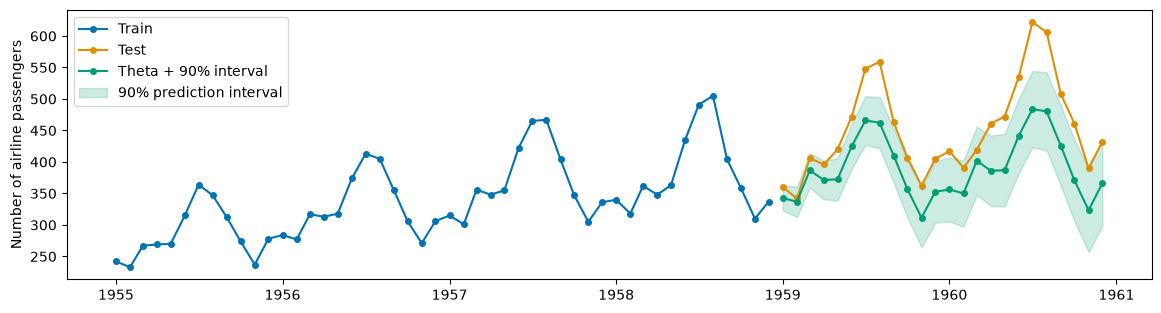

In [32]:
plot_series(
    y_train.tail(48),
    y_test,
    theta.predict(),
    labels=["Train", "Test", "Theta + 90% interval"],
    pred_interval=theta_int,
);

Looks reasonable, but **an interval is a claim, and we can check it**: how many of the true test values are really inside? That is the *empirical coverage*. For a 90% interval it should be close to 90%.

In [33]:
from sktime.performance_metrics.forecasting.probabilistic import EmpiricalCoverage

EmpiricalCoverage(coverage=0.9)(y_test, theta_int)

np.float64(0.2916666666666667)

Far too low: the interval is **too narrow**, the model is overconfident. (Theta assumes the noise does not grow with the level, but our seasonal swings do.)

**Fix for any forecaster:** `ConformalIntervals` wraps a forecaster and turns its *past backtest errors* into prediction intervals. It works for models without native intervals, like our random forest pipeline. We put it as the last step, and `sktime` transforms the interval back to the original scale for us:

Coverage: 0.9166666666666666


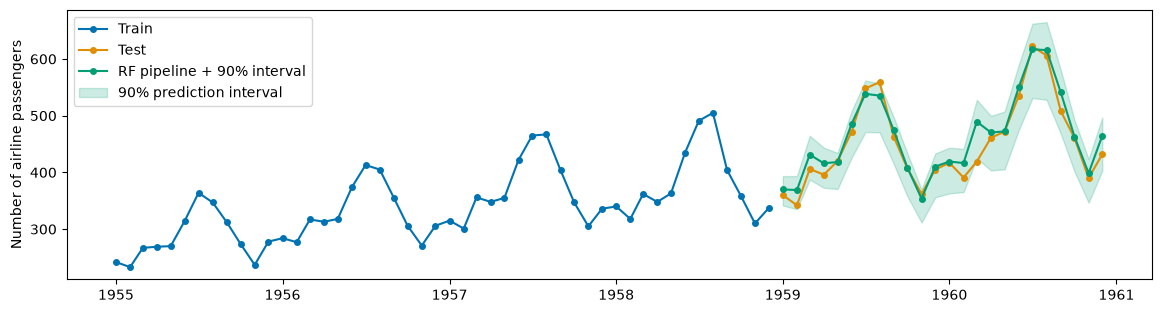

In [34]:
from sktime.forecasting.conformal import ConformalIntervals

pipe_ci = (
    LogTransformer()
    * Deseasonalizer(sp=12, model="multiplicative")
    * Detrender()
    * ConformalIntervals(
        make_reduction(RandomForestRegressor(random_state=0), window_length=12),
        initial_window=48,
    )
)
pipe_ci.fit(y_train, fh=fh)
pipe_int = pipe_ci.predict_interval(coverage=0.9)

plot_series(
    y_train.tail(48),
    y_test,
    pipe_ci.predict(),
    labels=["Train", "Test", "RF pipeline + 90% interval"],
    pred_interval=pipe_int,
);
print("Coverage:", EmpiricalCoverage(coverage=0.9)(y_test, pipe_int))

### ✏️ Exercise: Which coverage can you trust?

Compare the two models for the coverages 50%, 80% and 90%:

* `theta` (native intervals)
* `pipe_ci` (conformal intervals)

For each coverage, call `predict_interval(coverage=...)` and compute the empirical coverage on `y_test` with `EmpiricalCoverage`. Print a small table. **Which model keeps its promise?**

*Careful: the test set has only 24 points, so a few points more or less move the numbers a lot.*

In [35]:
# --- Solution (instructor version only) ---
rows = {}
for c in [0.5, 0.8, 0.9]:
    cov = EmpiricalCoverage(coverage=c)
    rows[c] = {
        "theta": cov(y_test, theta.predict_interval(coverage=c)),
        "pipe_ci": cov(y_test, pipe_ci.predict_interval(coverage=c)),
    }

pd.DataFrame(rows).T

,theta,pipe_ci
0.5,0.083333,0.708333
0.8,0.125000,0.875000
0.9,0.291667,0.916667


⏱️ **Instructor timing**

**2:55-2:58 · 2.4 leaderboard (3 min).** Just run the cell and read it out.

## 2.4 Leaderboard so far

Let's collect all our models in one table. This is our reference for the end of the day.

In [36]:
from sktime.forecasting.theta import ThetaForecaster

leaderboard = pd.Series(
    {
        "Seasonal naive": backtest(NaiveForecaster(strategy="last", sp=12)),
        "ETS": backtest(ExponentialSmoothing(trend="add", seasonal="mul", sp=12)),
        "Theta": backtest(ThetaForecaster(sp=12)),
        "Random forest (plain)": backtest(rf),
        "Pipeline: log → deseason → detrend → RF": backtest(pipe_long),
    },
    name="MAPE",
).sort_values()

leaderboard.to_frame().style.format("{:.1%}")

,MAPE
ETS,4.0%
Pipeline: log → deseason → detrend → RF,4.2%
Theta,6.4%
Random forest (plain),8.6%
Seasonal naive,10.7%


⏱️ **Instructor timing**

**2:58-3:05 · 3.1 panel and hierarchical data (7 min).** ✅ Checkpoint: Block 3 should start at 2:58 (2:43 if you skipped 1.5 and the 2.3 exercise).

---
# Block 3 · Many series at once: panel and hierarchical data (32 min)

## 3.1 What is panel and hierarchical data?

In practice you rarely forecast one series. A retailer forecasts **thousands** of products and stores.

* **Panel data** = many series of the same kind (one per product, store, sensor, ...)
* **Hierarchical data** = panel data where the series **add up**: products → product groups → company total

<img src="imgs/hierarchical_data_tree.png" style="max-width: 600px" />

In `sktime` this is a `pandas` DataFrame with a **`MultiIndex`**: the last level is time, the levels before identify the series.

In [37]:
from sktime.datasets import load_hierarchical_sales_toydata

y_h = load_hierarchical_sales_toydata()
y_h.head(8)

Sales
Product line     Product group Date          
Food preparation Hobs          2000-01  245.0
                               2000-02  144.0
                               2000-03  184.0
                               2000-04  265.0
                               2000-05  236.0
                               2000-06   97.0
                               2000-07  190.0
                               2000-08  135.0

Four series on the bottom level: two product lines with two product groups each. The `Aggregator` transformer adds the **aggregated series** (`__total`) of the hierarchy:

In [38]:
from sktime.transformations.hierarchical.aggregate import Aggregator

y_h = Aggregator().fit_transform(y_h)

y_h.index.droplevel(-1).unique().to_frame(index=False)

,Product line,Product group
0,Food preparation,Hobs
1,Food preparation,Ovens
2,Food preparation,__total
3,Food preservation,Freezers
4,Food preservation,Fridges
5,Food preservation,__total
6,__total,__total


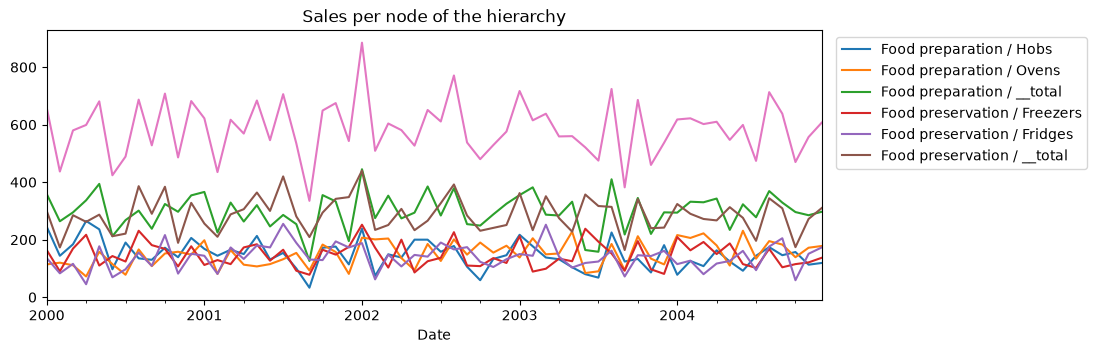

In [39]:
fig, ax = plt.subplots()
for (line, group), s in y_h.groupby(level=[0, 1]):
    s.droplevel([0, 1])["Sales"].plot(ax=ax, label=f"{line} / {group}", legend=True)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
ax.set_title("Sales per node of the hierarchy");

⏱️ **Instructor timing**

**3:05-3:15 · 3.2 broadcasting + exercise (10 min).** Exercise 5 min.

## 3.2 Forecasting many series: it just works (*broadcasting*)

Every forecaster we saw before can be applied directly to panel data. `sktime` **broadcasts**: it fits one copy of the forecaster per series.

<img src="imgs/broadcasting.png" style="max-width: 800px" />

In [40]:
y_h_train, y_h_test = temporal_train_test_split(y_h, test_size=12)
fh_h = np.arange(1, 13)

ets_h = ExponentialSmoothing(trend="add", seasonal="mul", sp=12)
ets_h.fit(y_h_train, fh=fh_h)
y_h_pred = ets_h.predict()

y_h_pred.head(4)

Sales
Product line     Product group Date               
Food preparation Hobs          2004-01  174.175609
                               2004-02  107.690602
                               2004-03  128.322611
                               2004-04  139.900848

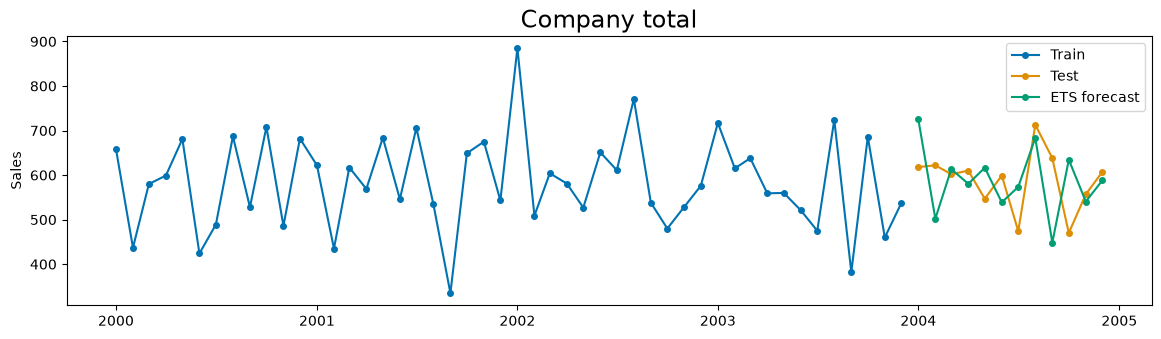

In [41]:
total = ("__total", "__total")
plot_series(
    y_h_train.loc[total]["Sales"],
    y_h_test.loc[total]["Sales"],
    y_h_pred.loc[total]["Sales"],
    labels=["Train", "Test", "ETS forecast"],
    title="Company total",
);

### ✏️ Exercise: A different forecaster for all series

Use a **different** forecaster for all seven series: `ThetaForecaster(sp=12)`. Then compute the MAE **per series** with `MeanAbsoluteError(multilevel="raw_values")`.

Which node of the hierarchy has the largest error? (Is that surprising?)

In [42]:
# --- Solution (instructor version only) ---
from sktime.forecasting.theta import ThetaForecaster

theta_h = ThetaForecaster(sp=12)
theta_h.fit(y_h_train, fh=fh_h)
y_h_pred_theta = theta_h.predict()

mae_per_series = MeanAbsoluteError(multilevel="raw_values")
mae_per_series(y_h_test, y_h_pred_theta)

# The total has the largest absolute error simply because it has the largest values.

MeanAbsoluteError
Food preparation  Hobs              38.171419
                  Ovens             39.279882
                  __total           48.297825
Food preservation Freezers          28.302666
                  Fridges           43.815839
                  __total           44.303804
__total           __total           71.528125

⏱️ **Instructor timing**

**3:15-3:30 · 3.3 incoherence and 3.4 reconciliation (15 min).** The 🌟 bonus exercise at the end of 3.4 is **SKIPPABLE** and not in the timeline (+5 min if you do it).

## 3.3 The problem: forecasts that don't add up

We forecasted every series **independently**. So nothing forces the forecasts of the four products to add up to the forecast of the total. Let's check:

In [43]:
def coherence_gap(y_pred):
    """Largest gap between the sum of the 4 bottom series and the forecast of the total."""
    idx = y_pred.index
    is_bottom = (idx.get_level_values(0) != "__total") & (idx.get_level_values(1) != "__total")
    bottom_sum = y_pred[is_bottom].groupby(level=-1).sum()["Sales"].to_numpy()
    total_fc = y_pred.loc[("__total", "__total")]["Sales"].to_numpy()
    return float(np.abs(bottom_sum - total_fc).max())


print(f"Largest gap between bottom sum and total: {coherence_gap(y_h_pred):.1f} units")

Largest gap between bottom sum and total: 51.0 units


Two departments would plan with different numbers. This is the **incoherence problem** of hierarchical forecasting.

<img src="imgs/hierarchical_data_tree_unreconciled.png" style="max-width: 600px" />

## 3.4 The solution: reconciliation

**Reconciliation** adjusts the forecasts of all nodes, so that they add up again, *and* it tends to make them better, because information from all levels is combined.

<img src="imgs/hierarchical_data_tree_reconciled.png" style="max-width: 600px" />

In `sktime`, wrap your forecaster in a `ReconcilerForecaster`. We use the `mint_shrink` method (*MinT*: minimum-trace reconciliation, which takes the correlation of forecast errors into account):

In [44]:
from sktime.forecasting.reconcile import ReconcilerForecaster

reconciled = ReconcilerForecaster(
    forecaster=ExponentialSmoothing(trend="add", seasonal="mul", sp=12),
    method="mint_shrink",
)
reconciled.fit(y_h_train)
y_h_pred_rec = reconciled.predict(fh=fh_h)

print(f"Gap before: {coherence_gap(y_h_pred):7.1f}")
print(f"Gap after:  {coherence_gap(y_h_pred_rec):7.1f}")

Gap before:    51.0
Gap after:      0.0


This is the month with the largest gap, before and after reconciliation:

<img src="imgs/reconciliation.png" style="max-width: 800px" />

In [45]:
mae_all = MeanAbsoluteError(multilevel="uniform_average")

pd.Series(
    {
        "independent ETS": mae_all(y_h_test, y_h_pred),
        "reconciled (MinT)": mae_all(y_h_test, y_h_pred_rec),
    },
    name="mean MAE over all 7 series",
).to_frame()

,mean MAE over all 7 series
independent ETS,46.129809
reconciled (MinT),46.334924


On this tiny toy dataset the accuracy is about the same: **the main gain is coherence** (all numbers add up, so everyone plans with the same figures). On larger hierarchies, reconciliation often improves accuracy too.

### 🌟 Bonus: Compare reconciliation methods

`sktime` has several reconciliation methods. Try `"bu"` (bottom-up: just sum the bottom forecasts), `"ols"` and `"wls_str"` in the same wrapper and compare the mean MAE as above. Does one stand out?

In [46]:
# --- Solution (instructor version only) ---
scores = {}
for method in ["bu", "ols", "wls_str"]:
    rec = ReconcilerForecaster(
        forecaster=ExponentialSmoothing(trend="add", seasonal="mul", sp=12),
        method=method,
    )
    rec.fit(y_h_train)
    scores[method] = mae_all(y_h_test, rec.predict(fh=fh_h))

pd.Series(scores)

bu         47.222987
ols        45.818115
wls_str    46.235510
dtype: float64

⏱️ **Instructor timing**

**3:30-3:40 · 4.1 zero-shot forecast and 4.2 backtest (10 min).** ✅ Checkpoint 3:30: Block 3 done.

---
# Block 4 · Foundation models as drop-in forecasters (37 min)

## 4.1 What is a time series foundation model?

A **foundation model** (FM) is a model that someone else **pre-trained on a huge, diverse collection of time series**. You download the weights and forecast **without training on your data** (*zero-shot*): the model just reads your history as context.

<img src="imgs/global-fcst.png" style="max-width: 600px" />

`sktime` wraps many FMs as ordinary forecasters. You already know the interface:

<img src="imgs/fm-simple.png" style="max-width: 600px" />

We use **Chronos-Bolt (tiny)** from Amazon: 9 million parameters, runs on a laptop CPU, Apache-2.0 license.

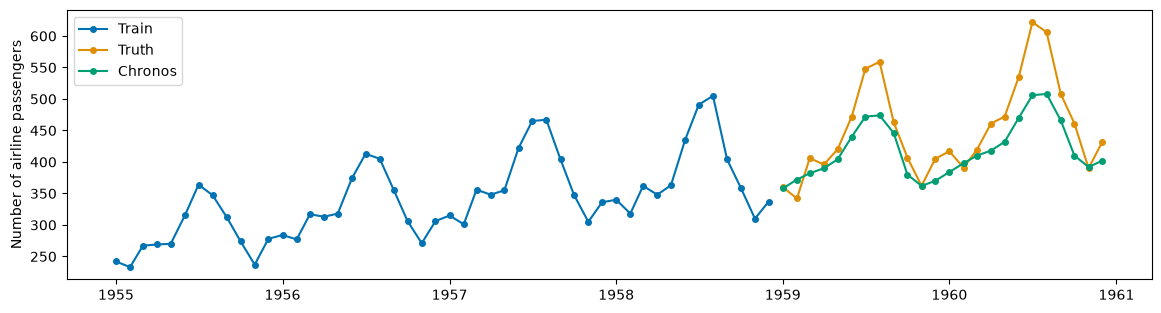

In [47]:
FALLBACK_FILE = "data/chronos_airline_fallback.csv"  # stored predictions, used only if the model cannot be loaded

y_train_fm = y.iloc[:-24]
fh_fm = np.arange(1, 25)

if CHRONOS_OK:
    chronos = ChronosForecaster("amazon/chronos-bolt-tiny")
    chronos.fit(y_train_fm)  # zero-shot: "fit" does not train anything on our data
    y_pred_chronos = chronos.predict(fh=fh_fm)
else:
    print("Using stored predictions (offline fallback).")
    y_pred_chronos = pd.read_csv(FALLBACK_FILE, index_col=0).squeeze("columns")
    y_pred_chronos.index = pd.PeriodIndex(y_pred_chronos.index, freq="M")

plot_series(y_train_fm.tail(48), y.iloc[-24:], y_pred_chronos, labels=["Train", "Truth", "Chronos"]);

## 4.2 Trust, but verify: backtest on your own data

Marketing says that every foundation model is the best on some leaderboard. The only honest test is **your data and your backtest**. Same splitter, same metric as in Block 2:

In [48]:
if CHRONOS_OK:
    leaderboard["Chronos-Bolt tiny (zero-shot)"] = backtest(
        ChronosForecaster("amazon/chronos-bolt-tiny")
    )

leaderboard.sort_values().to_frame().style.format("{:.1%}")

,MAPE
ETS,4.0%
Pipeline: log → deseason → detrend → RF,4.2%
Theta,6.4%
Chronos-Bolt tiny (zero-shot),6.4%
Random forest (plain),8.6%
Seasonal naive,10.7%


⏱️ **Instructor timing**

**3:40-3:50 · 4.3 context (10 min). ⏭️ SKIPPABLE (-10 min).** LLM-vs-TSFM table 3 min, context demo 4 min, discussion 3 min. The 🌟 bonus exercise is **SKIPPABLE** and not in the timeline.

## 4.3 Context = the prompt

If you have used ChatGPT or any other large language model (LLM), you already know how a foundation model for time series works:

<img src="imgs/llm_vs_tsfm.png" style="max-width: 900px" />

| LLM | time series foundation model (TSFM) |
|---|---|
| **prompt** you write | **context**: the history you give the model |
| tokens (words, word pieces) | values of the series (Chronos-Bolt: patches of 16 values) |
| pre-trained on huge text corpora | pre-trained on huge collections of time series |
| *zero-shot*: just prompt it, no training | *zero-shot*: `fit` only stores the history as context |
| fine-tuning is optional | fine-tuning is optional |
| **continues** the text | **continues** the series = the forecast |
| maximal context window (in tokens) | maximal context window (Chronos-Bolt: 2048 values) |

Two differences: a TSFM has **no instructions**, its only job is "continue this series". And while the original Chronos generates its forecast step by step like an LLM generates words, Chronos-Bolt predicts the whole horizon in one go.

In `sktime`, the context is **whatever history you pass to the model**. Until now, the model saw *all* data before every backtest window (between 72 and 132 months). **What if we only show it the last 48 months?** Is there anything to learn from the series that is further back?

all history        6.4%
last 48 months    10.4%


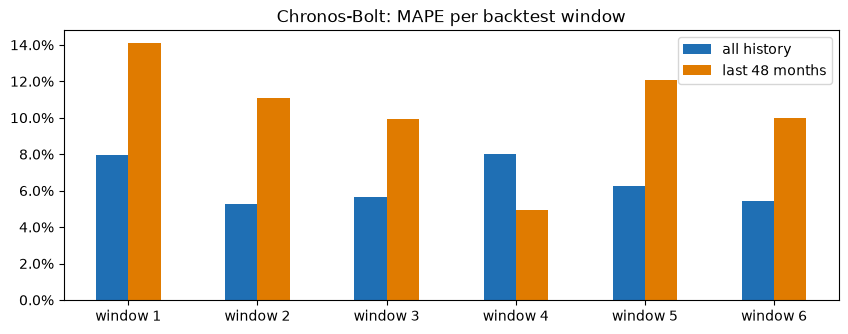

In [49]:
fh_12 = np.arange(1, 13)


def backtest_chronos(context_length=None):
    """MAPE per backtest window. The model only sees the last `context_length` months (None = all)."""
    errors = []
    for train_idx, test_idx in cv.split(y):
        if context_length is not None:
            train_idx = train_idx[-context_length:]  # cut the context
        chronos_ctx = ChronosForecaster("amazon/chronos-bolt-tiny").fit(y.iloc[train_idx])
        y_pred_ctx = chronos_ctx.predict(fh=fh_12)
        errors.append(mape(y.iloc[test_idx], y_pred_ctx))
    return pd.Series(errors, index=[f"window {i + 1}" for i in range(len(errors))])


if CHRONOS_OK:
    ctx_results = pd.DataFrame(
        {"all history": backtest_chronos(None), "last 48 months": backtest_chronos(48)}
    )
    ax = ctx_results.plot.bar(rot=0, color=[C_BLUE, C_ORANGE], title="Chronos-Bolt: MAPE per backtest window")
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    print(ctx_results.mean().map("{:.1%}".format).to_string())

Same model, same windows, same weights: only the **context** differs, and the error goes up substantially with the shorter context. The model has to infer *level, trend and seasonal pattern* from what it sees. With less history, it has less evidence for all three. (Not in every window though: in window 4 the shorter context was even better, which shows how much a single test window can mislead.)

### 🌟 Bonus: How much context is enough?

Run the backtest for the context lengths 12, 24, 36, 48, 60 and 72 months with `backtest_chronos(...)`, and plot the **mean error against the context length**.

Is more context always better?

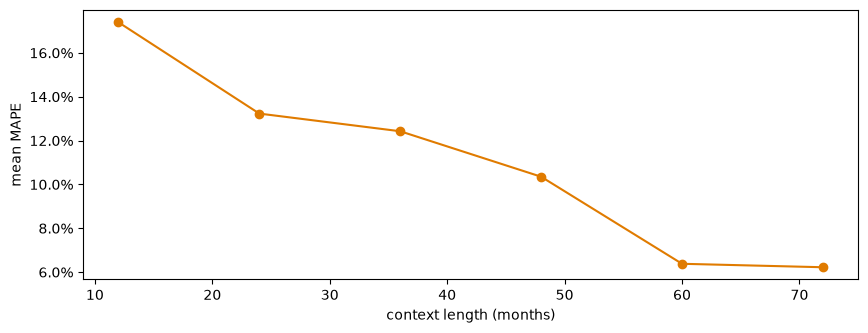

In [50]:
# --- Solution (instructor version only) ---
contexts = [12, 24, 36, 48, 60, 72]

mean_error = {c: backtest_chronos(c).mean() for c in contexts}

ax = pd.Series(mean_error).plot(marker="o", color=C_ORANGE)
ax.set_xlabel("context length (months)")
ax.set_ylabel("mean MAPE")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))

**Is "more context is better" true?** It is a good rule of thumb, but it comes with caveats:

* ✅ **Usually helps, up to a point.** More history means more seasons, a better idea of the level and trend. In our run the error fell from about 17% (12 months) to about 6% (60 months).
* ➖ **Diminishing returns.** Beyond 60 months, nothing improved any more: 72 months and the full history were as good as 60.
* ⚠️ **Not always monotone.** More context is not a guarantee at every step: the curve is bumpy, as 6 months even beat 12 months.
* ⚠️ **Old data can be wrong data.** After a structural break (new product, pandemic, price change), old history describes a world that no longer exists. Then *less* context can win.
* 🚫 **Models have a maximum.** Chronos-Bolt uses at most the last 2048 values; older data is cut off. And a longer context costs more compute.

As with LLM prompts: **relevant** context beats **a lot of** context. And as always: test it on your own data.

⏱️ **Instructor timing**

**3:50-4:02 · 4.4 hierarchy, intervals, shampoo exercise (12 min).** Hierarchical demo 3 min, conformal intervals 3 min (⏭️ **SKIPPABLE, -3 min**), shampoo exercise 6 min.

## 4.4 Everything you learned still works

Because the FM is a normal `sktime` forecaster, **hierarchical broadcasting** and **reconciliation** from Block 3 work out of the box. One copy of the model in memory, seven series.

(We use the `ols` reconciliation here: `mint_shrink` needs the model's *in-sample* errors, and a zero-shot foundation model cannot predict in-sample.)

In [51]:
if CHRONOS_OK:
    chronos_h = ChronosForecaster("amazon/chronos-bolt-tiny")
    chronos_h.fit(y_h_train)
    y_h_pred_chronos = chronos_h.predict(fh=fh_h)

    chronos_rec = ReconcilerForecaster(
        ChronosForecaster("amazon/chronos-bolt-tiny"), method="ols"
    )
    chronos_rec.fit(y_h_train)
    y_h_pred_chronos_rec = chronos_rec.predict(fh=fh_h)

    print(f"Gap Chronos:            {coherence_gap(y_h_pred_chronos):7.1f}")
    print(f"Gap Chronos reconciled: {coherence_gap(y_h_pred_chronos_rec):7.1f}")
    display(
        pd.Series(
            {
                "ETS": mae_all(y_h_test, y_h_pred),
                "ETS reconciled": mae_all(y_h_test, y_h_pred_rec),
                "Chronos": mae_all(y_h_test, y_h_pred_chronos),
                "Chronos reconciled (OLS)": mae_all(y_h_test, y_h_pred_chronos_rec),
            },
            name="mean MAE",
        ).to_frame()
    )

Gap Chronos:               21.0
Gap Chronos reconciled:     0.0


,mean MAE
ETS,46.129809
ETS reconciled,46.334924
Chronos,38.892857
Chronos reconciled (OLS),39.054989


And **prediction intervals** work, too. Chronos itself returns point forecasts here, but you know the trick from 2.3: wrap *any* forecaster in `ConformalIntervals`.

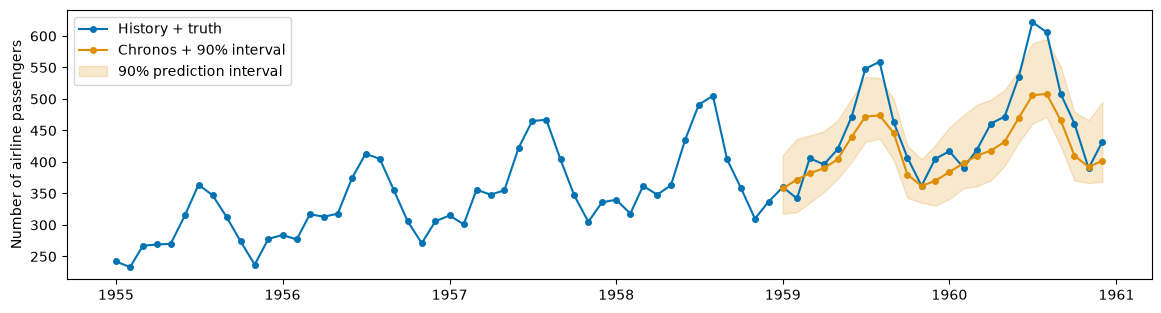

In [52]:
if CHRONOS_OK:
    from sktime.forecasting.conformal import ConformalIntervals

    chronos_conf = ConformalIntervals(
        ChronosForecaster("amazon/chronos-bolt-tiny"), initial_window=72
    )
    chronos_conf.fit(y_train_fm, fh=fh_fm)
    intervals = chronos_conf.predict_interval(coverage=0.9)

    plot_series(
        y.iloc[-72:],
        chronos_conf.predict(),
        labels=["History + truth", "Chronos + 90% interval"],
        pred_interval=intervals,
    );

### ✏️ Exercise: Your turn: another dataset

Does Chronos beat simple models on a **different** series? Use the *shampoo sales* data (`load_shampoo_sales`, 36 months, strong trend).

Backtest `NaiveForecaster(strategy="last")`, `ExponentialSmoothing(trend="add")` and `ChronosForecaster("amazon/chronos-bolt-tiny")` with the small splitter given below, and print the MAE of each (use `MeanAbsoluteError`). Who wins?

In [53]:
# --- Solution (instructor version only) ---
from sktime.datasets import load_shampoo_sales

y_shampoo = load_shampoo_sales()
cv_shampoo = ExpandingWindowSplitter(fh=[1, 2, 3], initial_window=24, step_length=3)

models = {
    "naive": NaiveForecaster(strategy="last"),
    "ets": ExponentialSmoothing(trend="add"),
    "chronos": ChronosForecaster("amazon/chronos-bolt-tiny"),
}

for name, model in models.items():
    res = evaluate(model, cv_shampoo, y_shampoo, scoring=MeanAbsoluteError())
    print(f"{name:8} MAE: {res['test_MeanAbsoluteError'].mean():.1f}")

naive    MAE: 101.0
ets      MAE: 73.2


chronos  MAE: 111.5


⏱️ **Instructor timing**

**4:02-4:07 · 4.5 openness (5 min).** Talk only.

## 4.5 Foundation models and openness

Before you put a foundation model into production, check **more than accuracy**:

* **Openness varies.** *Open weights* (like Chronos-Bolt on Hugging Face) can run **locally**: your data never leaves your machine. *Gated* models are paid APIs: you send your data to the provider.
* **Licenses are per artifact.** Weights, code, and data can have different licenses, and licenses can change. Read the model card.
* **Data protection and IP.** Sending business data to an API is a legal and strategic decision (GDPR, EU AI Act, trade secrets).
* **Reproducibility.** Pin library versions and weights. `sktime` ships stable wrappers with unified interfaces.

<img src="imgs/fm-license.png" style="max-width: 600px" />

**Rule of thumb:** *trust, but verify.* Benchmark on your own data and compare the pros and cons for your use case: simplicity, cost, interpretability, local vs. cloud.

⏱️ **Instructor timing**

**4:07-4:12 · Wrap-up (5 min).** The full path ends at **4:12**. To end at 4:00, skip 1.5 and the 2.3 exercise (-15 min, ends 3:57), and 4.3 as well if you need more buffer (-10 min).

---
# Wrap-up (5 min)

What you did today:

1. **`fit` / `predict` / `evaluate`**: one interface for naive, statistical, ML models, and foundation models
2. **Backtesting** instead of a single test set
3. **Pipelines** (`*` operator) and **tuning** on top of any forecaster
4. **Prediction intervals**: how to read them, and how to check them
5. **Panel and hierarchical data**: broadcasting and reconciliation
6. **Foundation models** are just another forecaster: *trust, but verify*

### Your recipe for Monday

1. **Start with a baseline**: a seasonal naive forecaster. Everything else has to beat it.
2. **Backtest**, don't trust a single test set: one splitter, one metric, for all models.
3. **Add structure** with pipelines: transform the target, add features, then fit the model.
4. **Tune** with backtesting as the judge, and keep a final holdout.
5. **Check the intervals**: does a 90% interval really cover 90%?
6. **Compare with a foundation model**: same interface, same backtest. Trust, but verify.

**Not covered today (but in `sktime`):** probabilistic forecasting in depth (quantiles, distributions), global forecasting, deep learning, anomaly detection, classification and clustering of time series, AutoML, benchmarking...

### Where to go next
* Docs and tutorials: <https://www.sktime.net>
* The full course this workshop is based on: <https://github.com/sktime/forecasting-course>
* Source code, issues, contributions: <https://github.com/sktime/sktime>
* The sktime community is friendly. Questions and first contributions are welcome.

**Thank you! 🙏**